# Desafio 2 — Classificação da categoria do cliente

Classificar o cliente em Bronze, Prata, Ouro ou Platinum para a oferta. O modelo entregue é um `RandomForestClassifier`. `Renda` fica de fora: ela está ligada à categoria e tornaria o problema trivial.


In [1]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="whitegrid")
SEMENTE = 42
ORDEM_CATEGORIA = ["Bronze", "Prata", "Ouro", "Platinum"]


## Exploração

A distribuição das classes motiva o split estratificado e o `f1_macro`: Bronze é a classe maior e Platinum, a menor. Os boxplots e a ANOVA mostram como as numéricas se separam por categoria. A ANOVA da renda documenta a associação que tira essa coluna do modelo. O qui-quadrado testa `Escolaridade` e `Estado_Civil` contra a categoria.


In [2]:
base = pd.read_csv("datasets/clientes.csv")
base.info()
display(base.head())
display(base["Categoria_Cliente"].value_counts().reindex(ORDEM_CATEGORIA))


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID_Cliente           2000 non-null   int64  
 1   Nome                 2000 non-null   str    
 2   Idade                2000 non-null   int64  
 3   Escolaridade         2000 non-null   str    
 4   Tempo_Emprego        2000 non-null   int64  
 5   Estado_Civil         2000 non-null   str    
 6   Dependentes          2000 non-null   int64  
 7   Score_Credito        2000 non-null   int64  
 8   Gasto_Mensal_Cartao  2000 non-null   float64
 9   Investimentos        2000 non-null   float64
 10  Dividas              2000 non-null   float64
 11  Renda                2000 non-null   float64
 12  Categoria_Cliente    2000 non-null   str    
dtypes: float64(4), int64(5), str(4)
memory usage: 203.3 KB


,ID_Cliente,Nome,Idade,Escolaridade,Tempo_Emprego,Estado_Civil,Dependentes,Score_Credito,Gasto_Mensal_Cartao,Investimentos,Dividas,Renda,Categoria_Cliente
0,1,Bruno Ferreira Gomes,22,Fundamental,1,Divorciado,1,210,451.73,882.43,17089.75,3530.80,Bronze
1,2,Bruno Barbosa Cardoso,59,Médio,5,Casado,2,482,1569.73,6989.56,6537.04,6087.50,Prata
2,3,Beatriz Correia Souza,52,Fundamental,10,Casado,1,585,468.87,6300.54,1169.29,3249.91,Prata
3,4,Mariana Lopes Vieira,41,Fundamental,7,Solteiro,2,661,442.77,12161.10,1433.53,3709.71,Prata
4,5,Fernanda Fernandes Lima,40,Superior,12,Casado,2,351,1457.27,8030.33,39111.05,11635.89,Bronze


Categoria_Cliente
Bronze      680
Prata       600
Ouro        440
Platinum    280
Name: count, dtype: int64

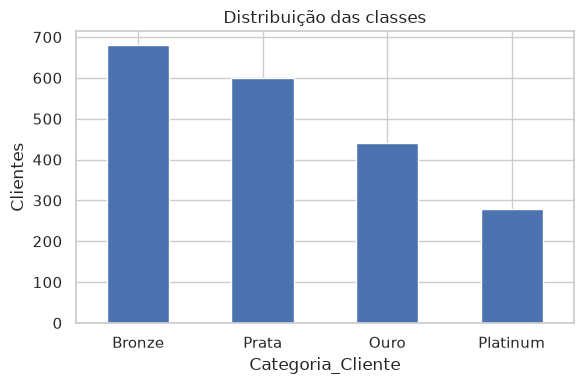

In [3]:
contagem = base["Categoria_Cliente"].value_counts().reindex(ORDEM_CATEGORIA)
contagem.plot(kind="bar", figsize=(6, 4), rot=0)
plt.ylabel("Clientes")
plt.title("Distribuição das classes")
plt.tight_layout()
plt.show()


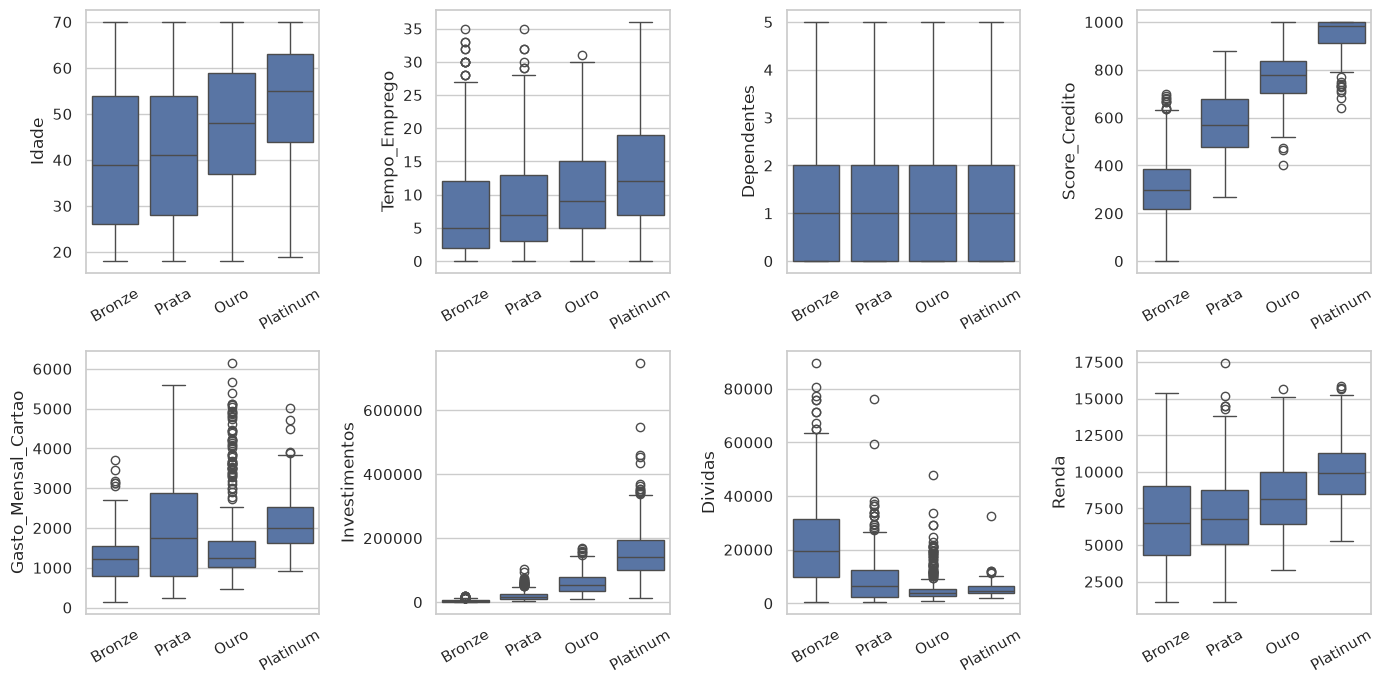

In [4]:
colunas_numericas = [
    "Idade",
    "Tempo_Emprego",
    "Dependentes",
    "Score_Credito",
    "Gasto_Mensal_Cartao",
    "Investimentos",
    "Dividas",
    "Renda",
]
fig, eixos = plt.subplots(2, 4, figsize=(14, 7))
for eixo, coluna in zip(eixos.ravel(), colunas_numericas):
    sns.boxplot(
        data=base,
        x="Categoria_Cliente",
        y=coluna,
        order=ORDEM_CATEGORIA,
        ax=eixo,
    )
    eixo.set_xlabel("")
    eixo.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


In [5]:
for coluna in colunas_numericas:
    grupos = [
        grupo[coluna].to_numpy()
        for _, grupo in base.groupby("Categoria_Cliente", observed=True)
    ]
    estatistica, valor_p = stats.f_oneway(*grupos)
    print(f"ANOVA {coluna}: F={estatistica:.2f}  p={valor_p:.4g}")

print()
for coluna in ["Escolaridade", "Estado_Civil"]:
    tabela = pd.crosstab(base[coluna], base["Categoria_Cliente"])
    chi2, valor_p, graus, _ = stats.chi2_contingency(tabela)
    print(f"Qui-quadrado {coluna}: chi2={chi2:.2f}  gl={graus}  p={valor_p:.4g}")


ANOVA Idade: F=49.73  p=5.448e-31
ANOVA Tempo_Emprego: F=42.91  p=7.23e-27
ANOVA Dependentes: F=0.01  p=0.9984
ANOVA Score_Credito: F=2686.43  p=0
ANOVA Gasto_Mensal_Cartao: F=89.53  p=2.348e-54
ANOVA Investimentos: F=1327.77  p=0
ANOVA Dividas: F=337.37  p=3.451e-177
ANOVA Renda: F=110.25  p=4.736e-66

Qui-quadrado Escolaridade: chi2=118.39  gl=9  p=2.859e-21
Qui-quadrado Estado_Civil: chi2=6.11  gl=9  p=0.7284


## Pré-processamento e modelos

Saem `ID_Cliente`, `Nome` e `Renda`. O split é estratificado pela categoria. Existem dois modelos, e a comparação é entre eles: a floresta com parâmetros padrão e a mesma floresta depois do `GridSearchCV`. A busca varia `n_estimators` e `max_depth`, com validação cruzada estratificada de 5 folds e `scoring="f1_macro"`. O one-hot fica dentro do pipeline e é reajustado a cada fold.


In [6]:
base_modelo = base.drop(columns=["ID_Cliente", "Nome", "Renda"])
colunas_numericas_modelo = [
    "Idade",
    "Tempo_Emprego",
    "Dependentes",
    "Score_Credito",
    "Gasto_Mensal_Cartao",
    "Investimentos",
    "Dividas",
]
colunas_categoricas_modelo = ["Escolaridade", "Estado_Civil"]

X = base_modelo.drop(columns=["Categoria_Cliente"])
y = base_modelo["Categoria_Cliente"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE, stratify=y
)

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
modelo = Pipeline(
    steps=[
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    ("numericas", "passthrough", colunas_numericas_modelo),
                    (
                        "categoricas",
                        OneHotEncoder(handle_unknown="ignore"),
                        colunas_categoricas_modelo,
                    ),
                ]
            ),
        ),
        ("floresta", RandomForestClassifier(random_state=SEMENTE)),
    ]
)

f1_baseline_cv = cross_val_score(
    modelo, X_treino, y_treino, cv=validacao, scoring="f1_macro"
)
busca = GridSearchCV(
    modelo,
    param_grid={
        "floresta__n_estimators": [100, 200, 400],
        "floresta__max_depth": [None, 8, 16],
    },
    cv=validacao,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
)
busca.fit(X_treino, y_treino)
modelo_categoria = busca.best_estimator_

print(f"F1 macro do baseline na validação cruzada: {f1_baseline_cv.mean():.4f}")
print(f"F1 macro do modelo tunado na validação cruzada: {busca.best_score_:.4f}")
print(f"Melhores parâmetros: {busca.best_params_}")


F1 macro do baseline na validação cruzada: 0.8119
F1 macro do modelo tunado na validação cruzada: 0.8121
Melhores parâmetros: {'floresta__max_depth': None, 'floresta__n_estimators': 200}


## Avaliação

O `classification_report`, a matriz de confusão e a importância das variáveis saem do modelo tunado, no teste. A importância da escolaridade e do estado civil fica repartida entre as dummies.


In [7]:
predito = modelo_categoria.predict(X_teste)
f1_macro = f1_score(y_teste, predito, average="macro")
print(classification_report(y_teste, predito, digits=3))
print(f"f1_macro no teste: {f1_macro:.3f}")

baseline = clone(modelo)
baseline.fit(X_treino, y_treino)
f1_baseline_teste = f1_score(y_teste, baseline.predict(X_teste), average="macro")
print(f"f1_macro do baseline no teste: {f1_baseline_teste:.3f}")


              precision    recall  f1-score   support

      Bronze      0.947     0.926     0.937       136
        Ouro      0.667     0.659     0.663        88
    Platinum      0.816     0.714     0.762        56
       Prata      0.763     0.833     0.797       120

    accuracy                          0.810       400
   macro avg      0.798     0.783     0.790       400
weighted avg      0.812     0.810     0.810       400

f1_macro no teste: 0.790


f1_macro do baseline no teste: 0.797


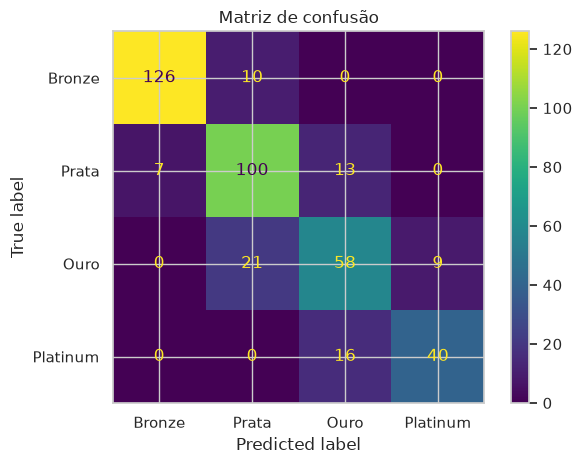

In [8]:
matriz = confusion_matrix(y_teste, predito, labels=ORDEM_CATEGORIA)
ConfusionMatrixDisplay(matriz, display_labels=ORDEM_CATEGORIA).plot()
plt.title("Matriz de confusão")
plt.tight_layout()
plt.show()


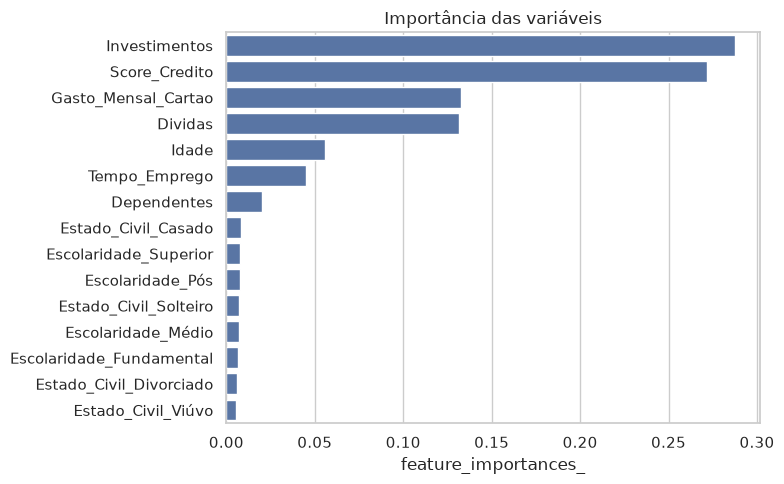

In [9]:
nomes_features = modelo_categoria.named_steps["preprocessor"].get_feature_names_out()
importancias = modelo_categoria.named_steps["floresta"].feature_importances_
tabela_importancias = pd.DataFrame(
    {"feature": nomes_features, "importancia": importancias}
)
tabela_importancias["feature"] = (
    tabela_importancias["feature"]
    .str.replace("numericas__", "", regex=False)
    .str.replace("categoricas__", "", regex=False)
)
tabela_importancias = tabela_importancias.sort_values("importancia", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=tabela_importancias, y="feature", x="importancia", color="C0")
plt.title("Importância das variáveis")
plt.xlabel("feature_importances_")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [10]:
joblib.dump(modelo_categoria, "modelo_categoria.pkl")


['modelo_categoria.pkl']

## Conclusões

O número de referência é o `f1_macro` no teste, de pelo menos 0,75. A comparação usa o baseline de um lado e o modelo tunado do outro.


In [11]:
f1_por_classe = pd.Series(
    f1_score(y_teste, predito, average=None, labels=ORDEM_CATEGORIA),
    index=ORDEM_CATEGORIA,
)
melhor_classe = f1_por_classe.idxmax()
pior_classe = f1_por_classe.idxmin()
print(
    f"O baseline teve f1_macro de {f1_baseline_cv.mean():.4f} na validação cruzada "
    f"e {f1_baseline_teste:.3f} no teste. "
    f"O modelo tunado teve {busca.best_score_:.4f} na validação cruzada "
    f"e f1_macro de {f1_macro:.3f} no teste. "
    "A busca escolhe pelo resultado da validação cruzada. "
    "No teste, o baseline ficou levemente acima, e a diferença é pequena. "
    "O arquivo salvo é o modelo escolhido na validação."
)
print(
    f"Melhor classe no teste: {melhor_classe} (F1={f1_por_classe[melhor_classe]:.3f}). "
    f"Pior classe no teste: {pior_classe} (F1={f1_por_classe[pior_classe]:.3f})."
)
print("F1 por classe:")
display(f1_por_classe.round(3).to_frame("f1"))


O baseline teve f1_macro de 0.8119 na validação cruzada e 0.797 no teste. O modelo tunado teve 0.8121 na validação cruzada e f1_macro de 0.790 no teste. A busca escolhe pelo resultado da validação cruzada. No teste, o baseline ficou levemente acima, e a diferença é pequena. O arquivo salvo é o modelo escolhido na validação.
Melhor classe no teste: Bronze (F1=0.937). Pior classe no teste: Ouro (F1=0.663).
F1 por classe:


,f1
Bronze,0.937
Prata,0.797
Ouro,0.663
Platinum,0.762
